# Week 9 — Sentiment & Text Analytics
### Turning review text into features, sentiment scores and topics
**SENG 42293 Big Data Analytics · LO3**

Text is the largest source of unstructured data. Analytics needs *numbers*, so the craft is converting words into representations a model can use, and knowing where each representation breaks.

**In this notebook:** text pre-processing · word frequencies · bag-of-words and **TF-IDF** · n-grams · a **lexicon** sentiment scorer (and its failure on negation) · a **machine-learned** classifier · error analysis · **topic modelling** · **aspect scorecards** · the same pipeline in **Spark ML**.

**Data:** the 15,000+ rated reviews of the semester project (`data/reviews_clean.csv`). 

> **Synthetic-data warning:** the review text was generated from templated phrases that depend on the rating. Real reviews are messier, so the *accuracies here are unrealistically high*. What transfers is the **method and the failure modes**.

In [1]:
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
ACC, ACCL, CH, GREY = "#8b7355", "#c4b5a0", "#2a2a2a", "#999999"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=[ACC, "#2a2a2a", ACCL, "#b5651d", "#6b8e8e", GREY]),
                     "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})
RES = {}                      # key numbers, reused in the slides and notes
def save(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130); plt.show()

In [2]:
import re
from collections import Counter
df = pd.read_csv("data/reviews_clean.csv").dropna(subset=["rating"]).reset_index(drop=True)
df["group"] = np.where(df.rating >= 4, "positive", np.where(df.rating <= 2, "negative", "neutral"))
print(df.shape, df.group.value_counts().to_dict())
for g in ["positive", "negative", "neutral"]:
    print(f"\n[{g}]"); print(*df[df.group == g].text.sample(3, random_state=1).tolist(), sep="\n")

(15183, 20) {'positive': 6974, 'neutral': 6711, 'negative': 1498}

[positive]
Comfortable bed, highly recommended.
Comfortable bed, amazing service.
Lovely garden, excellent breakfast, good value, highly recommended.

[negative]
Dirty bathroom, uncomfortable bed.
Rude staff, uncomfortable bed, disappointing breakfast, slow service.
Disappointing breakfast, noisy at night.

[neutral]
Average stay, close to the station.
Small room, amazing service, dirty bathroom.
Overpriced, small room, standard hotel, average stay.


## 1. Pre-processing pipeline
Typical steps: **lower-case → tokenise → remove punctuation/stop words → (stem or lemmatise)**. Each step discards information, so choose deliberately. Notice what we *keep*: negations such as `not`, because removing them destroys meaning.

In [3]:
STOP = set("a an the and or of to in on at is was were are it this that we i my our with for as be had has have from by very so".split())
tok = lambda t: re.findall(r"[a-z']+", t.lower())
df["tokens"] = df.text.apply(tok)
df["tokens_ns"] = df.tokens.apply(lambda ts: [w for w in ts if w not in STOP])
ex = df.text.iloc[0]; print("raw    :", ex); print("tokens :", tok(ex)); print("no stop:", [w for w in tok(ex) if w not in STOP])
print(f"\nvocabulary size: {len(set(w for ts in df.tokens_ns for w in ts))} distinct words in {len(df):,} reviews")
RES["vocab"] = len(set(w for ts in df.tokens_ns for w in ts))

raw    : Friendly staff, good value, highly recommended, peaceful location.
tokens : ['friendly', 'staff', 'good', 'value', 'highly', 'recommended', 'peaceful', 'location']
no stop: ['friendly', 'staff', 'good', 'value', 'highly', 'recommended', 'peaceful', 'location']

vocabulary size: 44 distinct words in 15,183 reviews


## 2. Word frequencies by sentiment group

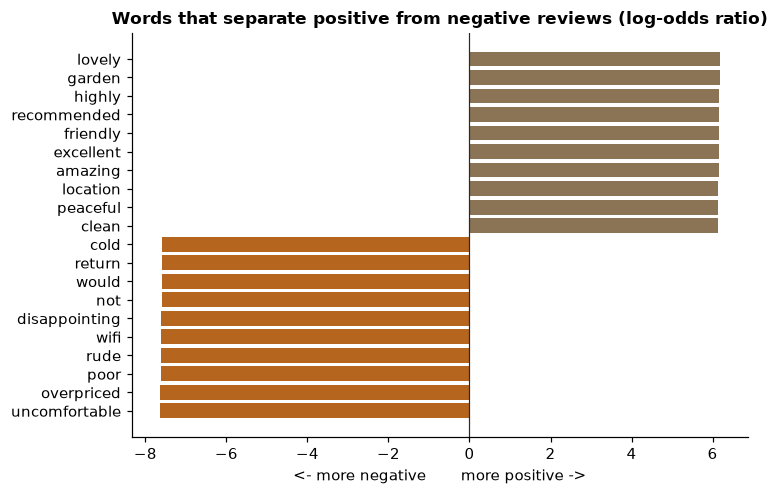

most positive: ['lovely', 'garden', 'highly', 'recommended', 'friendly'] | most negative: ['uncomfortable', 'overpriced', 'poor', 'rude', 'wifi']


In [4]:
cnt = {g: Counter(w for ts in df.loc[df.group == g, "tokens_ns"] for w in ts) for g in ["positive", "negative"]}
tot = {g: sum(c.values()) for g, c in cnt.items()}
vocab = set(cnt["positive"]) | set(cnt["negative"])
# log-odds ratio: positive when a word is relatively more frequent in positive reviews
lo = pd.Series({w: np.log((cnt["positive"][w] + 1) / tot["positive"]) - np.log((cnt["negative"][w] + 1) / tot["negative"]) for w in vocab if cnt["positive"][w] + cnt["negative"][w] >= 30}).sort_values()
fig, ax = plt.subplots(figsize=(7, 4.6)); sel = pd.concat([lo.head(10), lo.tail(10)])
ax.barh(sel.index, sel.values, color=[("#b5651d" if v < 0 else ACC) for v in sel.values]); ax.axvline(0, color=CH, lw=.8)
ax.set_title("Words that separate positive from negative reviews (log-odds ratio)"); ax.set_xlabel("<- more negative       more positive ->"); save("w09_logodds")
RES["top_pos_words"], RES["top_neg_words"] = lo.tail(5).index.tolist()[::-1], lo.head(5).index.tolist()
print("most positive:", RES["top_pos_words"], "| most negative:", RES["top_neg_words"])

## 3. Bag-of-words and TF-IDF
A document becomes a vector of word counts (**bag of words**: order is discarded). Raw counts over-weight common words, so **TF-IDF** rescales:

**tf-idf(t, d) = tf(t, d) × idf(t),   idf(t) = ln((1 + N) / (1 + df(t))) + 1**

A word that appears in *every* document (high *df*) gets a low weight; a word concentrated in a few documents gets a high weight.

In [5]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
docs = df.text.str.lower().tolist()
cv = CountVectorizer(stop_words=list(STOP)).fit(docs); Xc = cv.transform(docs)
tf = TfidfVectorizer(stop_words=list(STOP)).fit(docs); Xt = tf.transform(docs)
print(f"document-term matrix: {Xc.shape[0]:,} docs x {Xc.shape[1]} terms | non-zero cells: {Xc.nnz:,} | sparsity {(1 - Xc.nnz / (Xc.shape[0] * Xc.shape[1])):.1%}")
idf = pd.Series(tf.idf_, index=tf.get_feature_names_out()).sort_values()
print("lowest idf (most common):", idf.head(5).round(2).to_dict()); print("highest idf (rarest):   ", idf.tail(5).round(2).to_dict())
RES["dtm"] = [int(Xc.shape[0]), int(Xc.shape[1])]; RES["sparsity"] = round(1 - Xc.nnz / (Xc.shape[0] * Xc.shape[1]), 4)

document-term matrix: 15,183 docs x 44 terms | non-zero cells: 88,329 | sparsity 86.8%
lowest idf (most common): {'location': 2.2, 'staff': 2.48, 'breakfast': 2.48, 'service': 2.5, 'bed': 2.5}
highest idf (rarest):    {'poor': 3.85, 'wifi': 3.85, 'slow': 3.86, 'noisy': 3.87, 'night': 3.87}


**Sparsity** matters at scale. Our synthetic vocabulary has only 44 words, so about 87% of cells are zero; real review corpora have 100,000+ distinct terms and are over 99% zeros. Libraries therefore store only non-zero entries (sparse format), and Spark ML does the same with `SparseVector`.

## 4. N-grams: capturing short phrases
Unigrams lose context (`not` and `good` are separate). **Bigrams** keep adjacent pairs.

In [6]:
bg = CountVectorizer(ngram_range=(2, 2), stop_words=list(STOP), min_df=20).fit(df.loc[df.group != "neutral", "text"].str.lower())
for g in ["positive", "negative"]:
    M = bg.transform(df.loc[df.group == g, "text"].str.lower()); top = pd.Series(np.asarray(M.sum(0)).ravel(), index=bg.get_feature_names_out()).sort_values(ascending=False).head(6)
    print(f"top bigrams ({g}):", top.to_dict())

top bigrams (positive): {'lovely garden': 2161, 'highly recommended': 2128, 'friendly staff': 2113, 'excellent breakfast': 2104, 'amazing service': 2102, 'peaceful location': 2078}
top bigrams (negative): {'uncomfortable bed': 467, 'rude staff': 455, 'poor wifi': 455, 'disappointing breakfast': 447, 'not return': 442, 'would not': 442}


## 5. A lexicon-based sentiment scorer
Count positive and negative words from a dictionary. It needs no training data and is easy to explain (the Pipeline Guide used one).

In [7]:
POS = set("great friendly clean excellent peaceful comfortable amazing lovely good recommended".split())
NEG = set("noisy dirty rude slow overpriced uncomfortable poor cold disappointing".split())          # note: 'not' removed on purpose (see below)
NEGATORS = {"not", "never", "no"}
def lex(text, negation=False):
    ts, score = tok(text), 0
    for i, w in enumerate(ts):
        s = 1 if w in POS else -1 if w in NEG else 0
        if negation and s and any(t in NEGATORS for t in ts[max(0, i - 2):i]): s = -s       # flip within a 2-word window
        score += s
    return score
df["lex"] = df.text.apply(lex); df["lex_neg"] = df.text.apply(lambda t: lex(t, True))
sub = df[df.group != "neutral"]
acc = ((sub.lex > 0).astype(int) == (sub.group == "positive").astype(int)).mean()
from scipy.stats import spearmanr
print(f"lexicon vs rating group (pos/neg only): accuracy = {acc:.3f} | Spearman(lexicon score, rating) = {spearmanr(df.lex, df.rating)[0]:.3f}")
RES["lex_acc"], RES["lex_spearman"] = round(float(acc), 3), round(float(spearmanr(df.lex, df.rating)[0]), 3)

lexicon vs rating group (pos/neg only): accuracy = 1.000 | Spearman(lexicon score, rating) = 0.821


## 6. A machine-learned classifier
Instead of a hand-made dictionary, **learn** word weights from labelled data: TF-IDF features (unigrams + bigrams) into logistic regression. Neutral reviews are excluded (a 3-star review is genuinely ambiguous).

              precision    recall  f1-score   support

    negative      1.000     1.000     1.000       375
    positive      1.000     1.000     1.000      1743

    accuracy                          1.000      2118
   macro avg      1.000     1.000     1.000      2118
weighted avg      1.000     1.000     1.000      2118



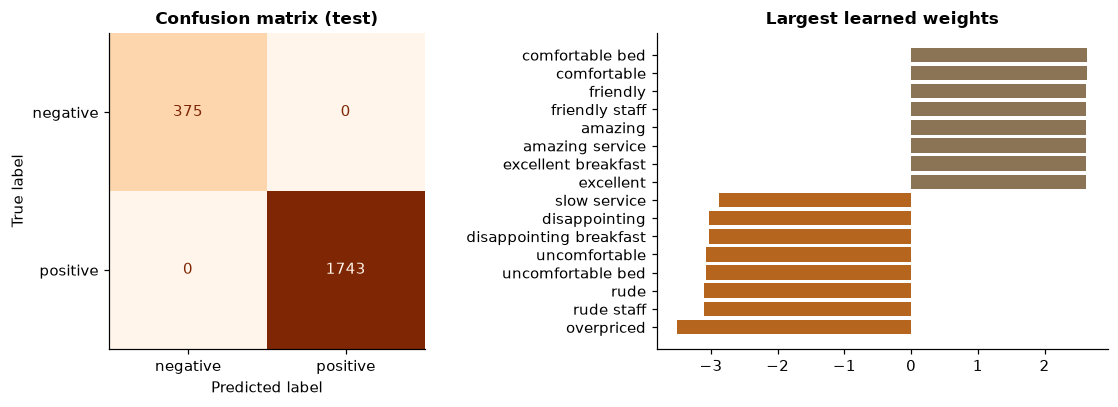

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score
y = (sub.group == "positive").astype(int)
Xtr, Xte, ytr, yte = train_test_split(sub.text.str.lower(), y, test_size=.25, random_state=42, stratify=y)
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, stop_words=None, sublinear_tf=True)          # keep stop words: 'not' matters
clf = LogisticRegression(max_iter=1000, C=3).fit(vec.fit_transform(Xtr), ytr)
pred = clf.predict(vec.transform(Xte))
print(classification_report(yte, pred, target_names=["negative", "positive"], digits=3))
RES["ml"] = {"acc": round(float(accuracy_score(yte, pred)), 4), "f1": round(float(f1_score(yte, pred)), 4)}
fig, ax = plt.subplots(1, 2, figsize=(10.5, 3.8))
ConfusionMatrixDisplay(confusion_matrix(yte, pred), display_labels=["negative", "positive"]).plot(ax=ax[0], cmap="Oranges", colorbar=False); ax[0].set_title("Confusion matrix (test)")
names = np.array(vec.get_feature_names_out()); co = clf.coef_[0]; idx = np.r_[np.argsort(co)[:8], np.argsort(co)[-8:]]
ax[1].barh(names[idx], co[idx], color=[("#b5651d" if c < 0 else ACC) for c in co[idx]]); ax[1].set_title("Largest learned weights")
save("w09_classifier")

**Reading the weights** shows what the model learned, an easy sanity check. Near-perfect scores here are a symptom of the synthetic text, not of an excellent model: real review classifiers typically reach roughly 85-93% accuracy, struggle with neutral and mixed reviews, and need far more data.

## 7. Where text models break: negation, sarcasm, mixed opinions
A tiny hand-written test set, each with the sentiment a human would assign. **Test on the hard cases, not only on the random split.**

In [9]:
tests = [("The staff were friendly and the room was clean", 1), ("The staff were not friendly", 0), ("Not a good stay, the room was dirty", 0),
         ("The bathroom was never dirty", 1), ("Poor wifi and a cold shower", 0), ("Not noisy at all, very peaceful", 1),
         ("Amazing view but the breakfast was disappointing and the service slow", 0), ("Would not recommend, rude staff", 0)]
rows = []
for t, truth in tests:
    rows.append({"text": t, "truth": truth, "lexicon": int(lex(t) > 0), "lexicon+negation": int(lex(t, True) > 0), "ML (TF-IDF+LR)": int(clf.predict(vec.transform([t.lower()]))[0])})
T = pd.DataFrame(rows); display(T)
accs = {c: float((T[c] == T.truth).mean()) for c in ["lexicon", "lexicon+negation", "ML (TF-IDF+LR)"]}
print("accuracy on the 8 hard sentences:", {k: round(v, 2) for k, v in accs.items()}); RES["hard_acc"] = {k: round(v, 3) for k, v in accs.items()}

,text,truth,lexicon,lexicon+negation,ML (TF-IDF+LR)
0,The staff were friendly and the room was clean,1,1,1,1
1,The staff were not friendly,0,1,0,1
2,"Not a good stay, the room was dirty",0,0,0,0
3,The bathroom was never dirty,1,0,1,0
4,Poor wifi and a cold shower,0,0,0,0
5,"Not noisy at all, very peaceful",1,0,1,0
6,Amazing view but the breakfast was disappointi...,0,0,0,0
7,"Would not recommend, rude staff",0,0,1,0


accuracy on the 8 hard sentences: {'lexicon': 0.62, 'lexicon+negation': 0.88, 'ML (TF-IDF+LR)': 0.62}


* The plain lexicon is fooled by negation (`not friendly` still scores +1).
* A simple **negation window** fixes many cases at no cost, but still cannot handle sarcasm or mixed opinions.
* The ML model only knows patterns present in its training data: if training text never contained negation, it cannot learn it. **Models inherit the limits of their data.**

## 8. Topic modelling: what are people talking about?
**Non-negative matrix factorisation (NMF)** decomposes the TF-IDF matrix into *topics* (groups of words that co-occur) and each review's topic weights. LDA is the classic probabilistic alternative.

topic 1 -> view, great, excellent, breakfast, comfortable, bed
topic 2 -> station, close, room, small, stay, average
topic 3 -> staff, service, amazing, friendly, clean, rude
topic 4 -> garden, lovely, clean, peaceful, location, friendly
topic 5 -> highly, recommended, value, good, clean, peaceful


,reviews,mean_rating
topic,,
1,1959,3.97
2,5426,2.96
3,3560,3.64
4,2325,4.25
5,1913,4.15


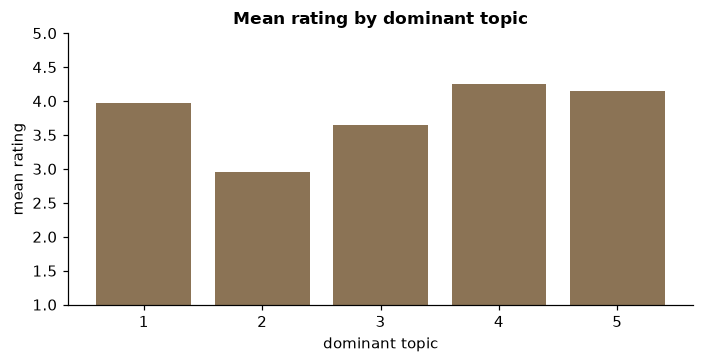

In [10]:
from sklearn.decomposition import NMF
tv = TfidfVectorizer(stop_words=list(STOP), min_df=10); Xn = tv.fit_transform(df.text.str.lower())
nmf = NMF(n_components=5, init="nndsvd", random_state=0, max_iter=500).fit(Xn); terms = np.array(tv.get_feature_names_out())
topics = {f"topic {i+1}": terms[np.argsort(c)[::-1][:6]].tolist() for i, c in enumerate(nmf.components_)}
for k, v in topics.items(): print(k, "->", ", ".join(v))
RES["topics"] = topics
W = nmf.transform(Xn); df["topic"] = W.argmax(1) + 1
share = df.groupby("topic").agg(reviews=("rating", "size"), mean_rating=("rating", "mean")).round(2); display(share)
fig, ax = plt.subplots(figsize=(6.5, 3.4)); ax.bar(share.index.astype(str), share.mean_rating, color=ACC); ax.set_ylim(1, 5); ax.set_xlabel("dominant topic"); ax.set_ylabel("mean rating"); ax.set_title("Mean rating by dominant topic"); save("w09_topics")
RES["topic_rating"] = share.mean_rating.to_dict()

Topics are *suggestions*, not facts: a human must **name** them by reading the top words. Here they separate the praise phrases from the complaint phrases, so their mean ratings differ sharply.

## 9. Aspect scorecard: actionable insight for a hotel manager
A single score hides *why*. **Aspect-based** analysis finds which parts of the stay drive satisfaction.

,aspect,mentions,share of reviews,mean rating when mentioned,% positive
4,wifi,880,0.058,2.396,0.000
8,shower,894,0.059,2.426,0.000
3,bed / room,5400,0.356,3.499,0.378
6,value / price,3450,0.227,3.744,0.600
0,staff / service,6131,0.404,3.755,0.599
2,breakfast,3439,0.227,3.765,0.612
7,noise / quiet,3380,0.223,3.772,0.615
1,cleanliness,3380,0.223,3.776,0.613
5,view / location,7936,0.523,3.940,0.609


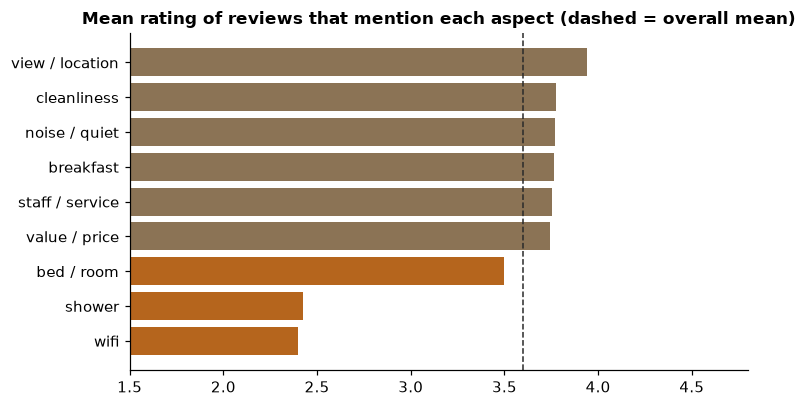

In [11]:
aspects = {"staff / service": ["staff", "service"], "cleanliness": ["clean", "dirty", "bathroom"], "breakfast": ["breakfast"], "bed / room": ["bed", "room"],
           "wifi": ["wifi"], "view / location": ["view", "location", "garden"], "value / price": ["value", "overpriced"], "noise / quiet": ["noisy", "peaceful"], "shower": ["shower"]}
rows = []
for a, kws in aspects.items():
    mask = df.tokens.apply(lambda ts: any(k in ts for k in kws))
    rows.append((a, int(mask.sum()), mask.mean(), df.rating[mask].mean(), (df.group[mask] == "positive").mean()))
sc = pd.DataFrame(rows, columns=["aspect", "mentions", "share of reviews", "mean rating when mentioned", "% positive"]).sort_values("mean rating when mentioned").round(3); display(sc)
RES["aspects"] = sc.to_dict("records")
fig, ax = plt.subplots(figsize=(7, 3.8)); ax.barh(sc.aspect, sc["mean rating when mentioned"], color=[("#b5651d" if v < df.rating.mean() else ACC) for v in sc["mean rating when mentioned"]])
ax.axvline(df.rating.mean(), color=CH, ls="--", lw=1); ax.set_xlim(1.5, 4.8); ax.set_title("Mean rating of reviews that mention each aspect (dashed = overall mean)"); save("w09_aspects")

In [12]:
# Per-hotel scorecard for one hotel: its weakest aspects compared with the platform
hid = df.hotel_id.value_counts().index[0]; hd = df[df.hotel_id == hid]; rows = []
for a, kws in aspects.items():
    mask_h = hd.tokens.apply(lambda ts: any(k in ts for k in kws)); mask_all = df.tokens.apply(lambda ts: any(k in ts for k in kws))
    if mask_h.sum() >= 5: rows.append((a, int(mask_h.sum()), hd.rating[mask_h].mean(), df.rating[mask_all].mean()))
card = pd.DataFrame(rows, columns=["aspect", "mentions", "this hotel", "platform"]).assign(gap=lambda d: d["this hotel"] - d["platform"]).sort_values("gap").round(2)
print("hotel:", hid, hd.hotel_name.iloc[0], "|", len(hd), "reviews"); display(card)

hotel: H-1218 Royal Residency 218 | 83 reviews


,aspect,mentions,this hotel,platform,gap
1,cleanliness,14,3.25,3.78,-0.53
7,shower,11,2.05,2.43,-0.38
5,value / price,17,3.44,3.74,-0.30
0,staff / service,41,3.48,3.76,-0.28
4,view / location,48,3.94,3.94,-0.00
2,breakfast,16,3.84,3.77,0.08
6,noise / quiet,22,3.91,3.77,0.14
3,bed / room,24,3.67,3.50,0.17


## 10. The same pipeline at scale: Spark ML
`RegexTokenizer → StopWordsRemover → CountVectorizer → IDF → LogisticRegression`. Each stage is distributed; the sparse vectors never leave the cluster.

In [13]:
import sys; os.environ["PYSPARK_PYTHON"] = sys.executable
from pyspark.sql import SparkSession, functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import RegexTokenizer, CountVectorizer as SCV, IDF
from pyspark.ml.classification import LogisticRegression as SLR
from pyspark.ml.evaluation import MulticlassClassificationEvaluator
spark = SparkSession.builder.master("local[*]").config("spark.ui.enabled", "false").getOrCreate(); spark.sparkContext.setLogLevel("ERROR")
sd = (spark.read.csv("data/reviews_clean.csv", header=True, inferSchema=True).filter(F.col("rating").isNotNull() & ((F.col("rating") >= 4) | (F.col("rating") <= 2)))
      .select("text", (F.col("rating") >= 4).cast("double").alias("label")))
train, test = sd.randomSplit([.75, .25], seed=42)
pipe = Pipeline(stages=[RegexTokenizer(inputCol="text", outputCol="tokens", pattern="[^a-z']+", toLowercase=True), SCV(inputCol="tokens", outputCol="tf", vocabSize=5000, minDF=3),
                        IDF(inputCol="tf", outputCol="features"), SLR(maxIter=50)])
model = pipe.fit(train); res = model.transform(test)
acc_s = MulticlassClassificationEvaluator(metricName="accuracy").evaluate(res); f1_s = MulticlassClassificationEvaluator(metricName="f1").evaluate(res)
print(f"Spark ML text classifier: accuracy = {acc_s:.4f}, F1 = {f1_s:.4f}  (scikit-learn: {RES['ml']['acc']})")
RES["spark_ml"] = {"acc": round(float(acc_s), 4), "f1": round(float(f1_s), 4)}
# word count at scale: the Week 4 activity on real data
top = (sd.select(F.explode(F.split(F.lower(F.regexp_replace("text", "[^a-zA-Z' ]", "")), " ")).alias("w")).filter(F.col("w") != "").groupBy("w").count().orderBy(F.desc("count")).limit(8).collect())
print("top words (Spark word count):", [(r.w, r["count"]) for r in top]); spark.stop()

Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1|::1|127.*|0.*|::|169.254.*|api.anthropic.com|api-staging.anthropic.com|api-pr-preview.anthropic.com|mcp-proxy.anthropic.com|mcp-proxy-staging.anthropic.com|registry.npmjs.org|jsr.io|npm.jsr.io|pypi.org|files.pythonhosted.org|index.crates.io|proxy.golang.org|host.docker.internal|10.*|172.16.*|172.17.*|172.18.*|172.19.*|172.20.*|172.21.*|172.22.*|172.23.*|172.24.*|172.25.*|172.26.*|172.27.*|172.28.*|172.29.*|172.30.*|172.31.*|192.168.*|100.64.0.0/10|*.svc.cluster.local|*.svc.cluster.local -Djdk.http.auth.tunneling.disabledSchemes= -Djdk.http.auth.proxying.disabledSchemes=
Picked up JAVA_TOOL_OPTIONS: -Djavax.net.ssl.trustStore=/etc/ssl/certs/java/cacerts -Djavax.net.ssl.trustStoreType=JKS -Dhttps.proxyHost=127.0.0.1 -Dhttps.proxyPort=44265 -Dhttp.nonProxyHosts=localhost|127.0.0.1

26/10/13 09:35:00 WARN Utils: Your hostname, vm resolves to a loopback address: 127.0.0.1; using 192.0.2.2 instead (on interface eth0)
26/10/13 09:35:00 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address


Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 09:35:00 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark ML text classifier: accuracy = 1.0000, F1 = 1.0000  (scikit-learn: 1.0)


top words (Spark word count): [('staff', 2568), ('breakfast', 2551), ('service', 2538), ('bed', 2509), ('lovely', 2161), ('garden', 2161), ('highly', 2128), ('recommended', 2128)]


## 11. Pitfalls and ethics
| Risk | Example | Mitigation |
|---|---|---|
| Negation / sarcasm | "not bad", "great, another delay" | negation handling, contextual models, human audit |
| Domain shift | model trained on hotels used on restaurants | re-train or fine-tune on target domain |
| Language & code-mixing | Sinhala/Tamil/English mixed reviews | language detection, multilingual models |
| Class imbalance | few negatives | stratified splits, F1/recall, resampling |
| Duplicates & fake reviews | copied or paid reviews | de-duplication, anomaly checks |
| Privacy | reviews can identify people | anonymise, minimise, follow consent and law |

## 12. Exercises
1. Add three more negators and a 3-word window to `lex`. Does accuracy on the hard sentences improve? Does it ever get *worse*?
2. Train the classifier **without** bigrams. Which hard sentences now fail?
3. Change NMF to 3 and 8 topics. Which setting gives the most interpretable topics? How would you decide objectively? (Hint: topic coherence.)
4. Build the aspect scorecard for the lowest-rated hotel with 40+ reviews. What would you recommend to its manager?
5. Why is the Spark pipeline's `minDF=3` filter important when the vocabulary is built across a cluster?

In [14]:
json.dump(RES, open("results/w09.json", "w"), indent=1); print(json.dumps(RES)[:1200])

{"vocab": 44, "top_pos_words": ["lovely", "garden", "highly", "recommended", "friendly"], "top_neg_words": ["uncomfortable", "overpriced", "poor", "rude", "wifi"], "dtm": [15183, 44], "sparsity": 0.8678, "lex_acc": 1.0, "lex_spearman": 0.821, "ml": {"acc": 1.0, "f1": 1.0}, "hard_acc": {"lexicon": 0.625, "lexicon+negation": 0.875, "ML (TF-IDF+LR)": 0.625}, "topics": {"topic 1": ["view", "great", "excellent", "breakfast", "comfortable", "bed"], "topic 2": ["station", "close", "room", "small", "stay", "average"], "topic 3": ["staff", "service", "amazing", "friendly", "clean", "rude"], "topic 4": ["garden", "lovely", "clean", "peaceful", "location", "friendly"], "topic 5": ["highly", "recommended", "value", "good", "clean", "peaceful"]}, "topic_rating": {"1": 3.97, "2": 2.96, "3": 3.64, "4": 4.25, "5": 4.15}, "aspects": [{"aspect": "wifi", "mentions": 880, "share of reviews": 0.058, "mean rating when mentioned": 2.396, "% positive": 0.0}, {"aspect": "shower", "mentions": 894, "share of rev